# Phase 3: Recommendation Model Development
**Movie Recommendation System | Kevin Basiye**

### Where this fits in the project
```
Phase 1 (Alex)       Phase 2 (Sheilla)        Phase 3 (Kevin)               Phase 4 (James)      Phase 5 (Julie)
Explore the data  →  Clean + train/test  →  BUILD THE MODEL           →  Evaluate it      →  Put it together
                     split (processed/)      + top-5 function
```

### Phase 3 tasks (from the project plan)
1. Research collaborative filtering techniques
2. Implement a collaborative filtering model
3. Explore **user-based and item-based** collaborative filtering
4. Train the model using Sheilla's prepared data
5. Generate predicted ratings for unseen movies
6. Generate the top five movie recommendations for selected users

**Deliverable:** a trained recommendation model and a recommendation function.

## 1. Research: what is collaborative filtering?

**Collaborative filtering (CF)** recommends movies using only the **ratings** people have given. It needs no information about the movies themselves (no genre, no actors). The idea: *people who agreed in the past will agree in the future.*

### The two families of CF
CF methods fall into **two families**. The first family, neighbourhood methods, comes in **two versions**, so three approaches are tested in total.

| Family | Version | How it works | Example |
|---|---|---|---|
| **1. Neighbourhood (KNN)**: predict from the most similar "neighbours" | **User-based** | Find the *k* users whose ratings are most similar to yours. Predict your rating from theirs. | "Users like you rated *Inception* 4.5" |
| | **Item-based** | Find the *k* movies most similar to the movie in question (rated similarly by the same people). Predict from how *you* rated those. | "You loved *The Matrix*, and *Inception* is rated like *The Matrix*" |
| **2. Matrix factorisation**: learn hidden taste factors | **SVD** | Learn a short list of hidden "taste factors" for every user and every movie. A rating is predicted by matching the user's tastes to the movie's factors. | A user who scores high on "likes sci-fi" × a movie that scores high on "is sci-fi" gives a high prediction |

*k* = the number of neighbours (users or movies) used for each prediction.

### Two ideas that appear in every model
* **Biases.** Some users rate everything high, and some movies are loved by everyone. Good models first predict `average rating + user bias + movie bias`, then learn the personal part on top. The **BaselineOnly** model does *only* this, which makes it a good benchmark.
* **Similarity.** KNN models need a way to measure how alike two users (or two movies) are. I use **Pearson correlation**: do they move up and down together? The `pearson_baseline` version compares ratings *after removing biases*, so a generous rater and a harsh rater with the same *taste* still count as similar.

### Library
I used **`scikit-surprise`**, a Python library built for rating-based recommenders. It handles training, cross-validation and predictions.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from surprise import Dataset, Reader, dump
from surprise import NormalPredictor, BaselineOnly, KNNWithMeans, KNNBaseline, SVD, NMF
from surprise.model_selection import cross_validate, GridSearchCV, KFold

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROCESSED_DIR = 'processed/'      # Sheilla's output folder (unzip processed.zip here)
OUTPUT_DIR = 'phase3_outputs/'    # what I hand to James and Julie
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. Load Sheilla's prepared data (Phase 2 output)

I used Sheilla's files **without changing them**, so every phase works from the same data:
* `train.csv` (80 % of each user's ratings) is used to **build and choose** the model
* `test.csv` (20 % of each user's ratings) is **held back for James**. I only *generate predictions* for it. I do not score them, because evaluation is Phase 4.
* `movies_clean.csv` holds titles and genres, used to display recommendations

In [2]:
train = pd.read_csv(PROCESSED_DIR + 'train.csv')
test = pd.read_csv(PROCESSED_DIR + 'test.csv')
movies = pd.read_csv(PROCESSED_DIR + 'movies_clean.csv')

# Check I received exactly what the Phase 2 report describes
assert len(train) == 80_672 and len(test) == 20_164, 'Row counts differ from the Phase 2 report'
assert train.userId.nunique() == 610 and test.userId.nunique() == 610
print(f'Train: {len(train):,} ratings | Test: {len(test):,} ratings | Users in both: {train.userId.nunique()}')
print(f'Movies in catalogue: {len(movies):,} | Movies with a rating in train: {train.movieId.nunique():,}')

unseen = ~test.movieId.isin(train.movieId)
print(f'Test ratings for movies the model never sees in training: {unseen.sum()} ({unseen.mean():.1%})')
train.head()

Train: 80,672 ratings | Test: 20,164 ratings | Users in both: 610
Movies in catalogue: 9,742 | Movies with a rating in train: 8,995
Test ratings for movies the model never sees in training: 790 (3.9%)


,userId,movieId,rating,timestamp,date,user_idx,movie_idx
0,1,1,4.0,964982703,2000-07-30 18:45:03,0,0
1,1,3,4.0,964981247,2000-07-30 18:20:47,0,2
2,1,6,4.0,964982224,2000-07-30 18:37:04,0,5
3,1,47,5.0,964983815,2000-07-30 19:03:35,0,43
4,1,50,5.0,964982931,2000-07-30 18:48:51,0,46


Sheilla's files contain extra columns (`timestamp`, `date`, `user_idx`, `movie_idx`). Surprise only needs **`userId, movieId, rating`**, and it handles its own internal indexing, so I keep just those three.

The **790 test ratings for unseen movies** matter: CF can't learn anything about a movie nobody rated in training. Section 5 explains how each model handles them.

In [3]:
reader = Reader(rating_scale=(0.5, 5.0))          # half-star scale used by MovieLens
folds = KFold(n_splits=5, random_state=RANDOM_STATE, shuffle=True)   # same 5 folds for every model -> fair, repeatable
cols = ['userId', 'movieId', 'rating']

train_data = Dataset.load_from_df(train[cols], reader)
trainset = train_data.build_full_trainset()

print(f'Surprise trainset: {trainset.n_users} users, {trainset.n_items:,} movies, {trainset.n_ratings:,} ratings')
print(f'Global average rating: {trainset.global_mean:.2f}')

Surprise trainset: 610 users, 8,995 movies, 80,672 ratings
Global average rating: 3.50


> **🧭 Decision: use Sheilla's split as-is, and only the columns `userId, movieId, rating`.**
> *How I decided:* I could have made my own split, but then each phase would be scored on different data. Her split also holds back 20 % of **every** user's ratings, so all 610 users can be tested, including light users, which the cold-start objective needs. CF only learns from who rated what and how highly, so the other columns aren't needed.

## 3. Implement and compare CF models

I trained **8 models** on the training data and compare them with **5-fold cross-validation**. The training set is split into 5 parts. Each model trains on 4 parts and is scored on the 5th, five times, and the scores are averaged. That gives a fair comparison **without touching the test set**. Every model uses the **same 5 folds** (fixed random seed), so the comparison is fair and anyone who reruns the notebook gets the same numbers.

The score is **RMSE**: how many stars off a predicted rating is, on average, with big misses punished more. Lower is better.

| Model | Type |
|---|---|
| NormalPredictor | Random guess (the floor every model must beat) |
| BaselineOnly | Average + user bias + movie bias (no personalisation) |
| KNNWithMeans, user-based | Neighbourhood, similar **users** |
| KNNBaseline, user-based | Same, compared after removing biases |
| KNNWithMeans, item-based | Neighbourhood, similar **movies** |
| KNNBaseline, item-based | Same, compared after removing biases |
| NMF | Matrix factorisation (non-negative factors) |
| SVD | Matrix factorisation (the Netflix Prize method) |

> **🧭 Decision: which models, and how to compare them?**
> * **Models:** at least one of each family from Section 1 (user-based KNN, item-based KNN, matrix factorisation), plus two **benchmarks**: random guessing and BaselineOnly. A model is only worth using if it beats the benchmarks.
> * **Two similarity measures for each KNN type** (`pearson` and `pearson_baseline`), to see whether removing biases helps.
> * **5-fold cross-validation on the training set only.** The test set is James's, and looking at it while choosing would make his scores too optimistic.
> * **RMSE as the main score, MAE as a second check.** Both are named in objective 3. RMSE punishes big misses, such as predicting 5 stars for a movie someone rated 1, which hurt users' trust the most.

*Memory note:* item-based KNN builds a movie-to-movie similarity table of about 9,000 × 9,000 (≈ 650 MB). I ran those models **one fold at a time** (`n_jobs=1`) so a laptop doesn't run out of memory. Everything else runs in parallel.

In [4]:
def item_sim(name):
    return {'name': name, 'user_based': False}

def user_sim(name):
    return {'name': name, 'user_based': True}

candidates = {
    'Random (NormalPredictor)':  (NormalPredictor(), -1),
    'BaselineOnly':              (BaselineOnly(verbose=False), -1),
    'KNNWithMeans, user-based':  (KNNWithMeans(k=40, sim_options=user_sim('pearson'), verbose=False), -1),
    'KNNBaseline, user-based':   (KNNBaseline(k=40, sim_options=user_sim('pearson_baseline'), verbose=False), -1),
    'KNNWithMeans, item-based':  (KNNWithMeans(k=40, sim_options=item_sim('pearson'), verbose=False), 1),
    'KNNBaseline, item-based':   (KNNBaseline(k=40, sim_options=item_sim('pearson_baseline'), verbose=False), 1),
    'NMF':                       (NMF(random_state=RANDOM_STATE), -1),
    'SVD':                       (SVD(random_state=RANDOM_STATE), -1),
}

rows = []
for name, (algo, jobs) in candidates.items():
    res = cross_validate(algo, train_data, measures=['RMSE', 'MAE'], cv=folds, n_jobs=jobs)
    rows.append({'model': name, 'RMSE': res['test_rmse'].mean(), 'RMSE_std': res['test_rmse'].std(),
                 'MAE': res['test_mae'].mean()})
    print(f'{name:27s} RMSE {res["test_rmse"].mean():.4f}   MAE {res["test_mae"].mean():.4f}')

comparison = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
comparison.round(4)

Random (NormalPredictor)    RMSE 1.4235   MAE 1.1362


BaselineOnly                RMSE 0.8745   MAE 0.6752


KNNWithMeans, user-based    RMSE 0.9077   MAE 0.6921


KNNBaseline, user-based     RMSE 0.8904   MAE 0.6786


KNNWithMeans, item-based    RMSE 0.9127   MAE 0.6950


KNNBaseline, item-based     RMSE 0.8623   MAE 0.6583


NMF                         RMSE 0.9323   MAE 0.7152


SVD                         RMSE 0.8801   MAE 0.6766


,model,RMSE,RMSE_std,MAE
0,"KNNBaseline, item-based",0.8623,0.0064,0.6583
1,BaselineOnly,0.8745,0.0050,0.6752
2,SVD,0.8801,0.0065,0.6766
3,"KNNBaseline, user-based",0.8904,0.0022,0.6786
4,"KNNWithMeans, user-based",0.9077,0.0031,0.6921
5,"KNNWithMeans, item-based",0.9127,0.0038,0.6950
6,NMF,0.9323,0.0068,0.7152
7,Random (NormalPredictor),1.4235,0.0065,1.1362


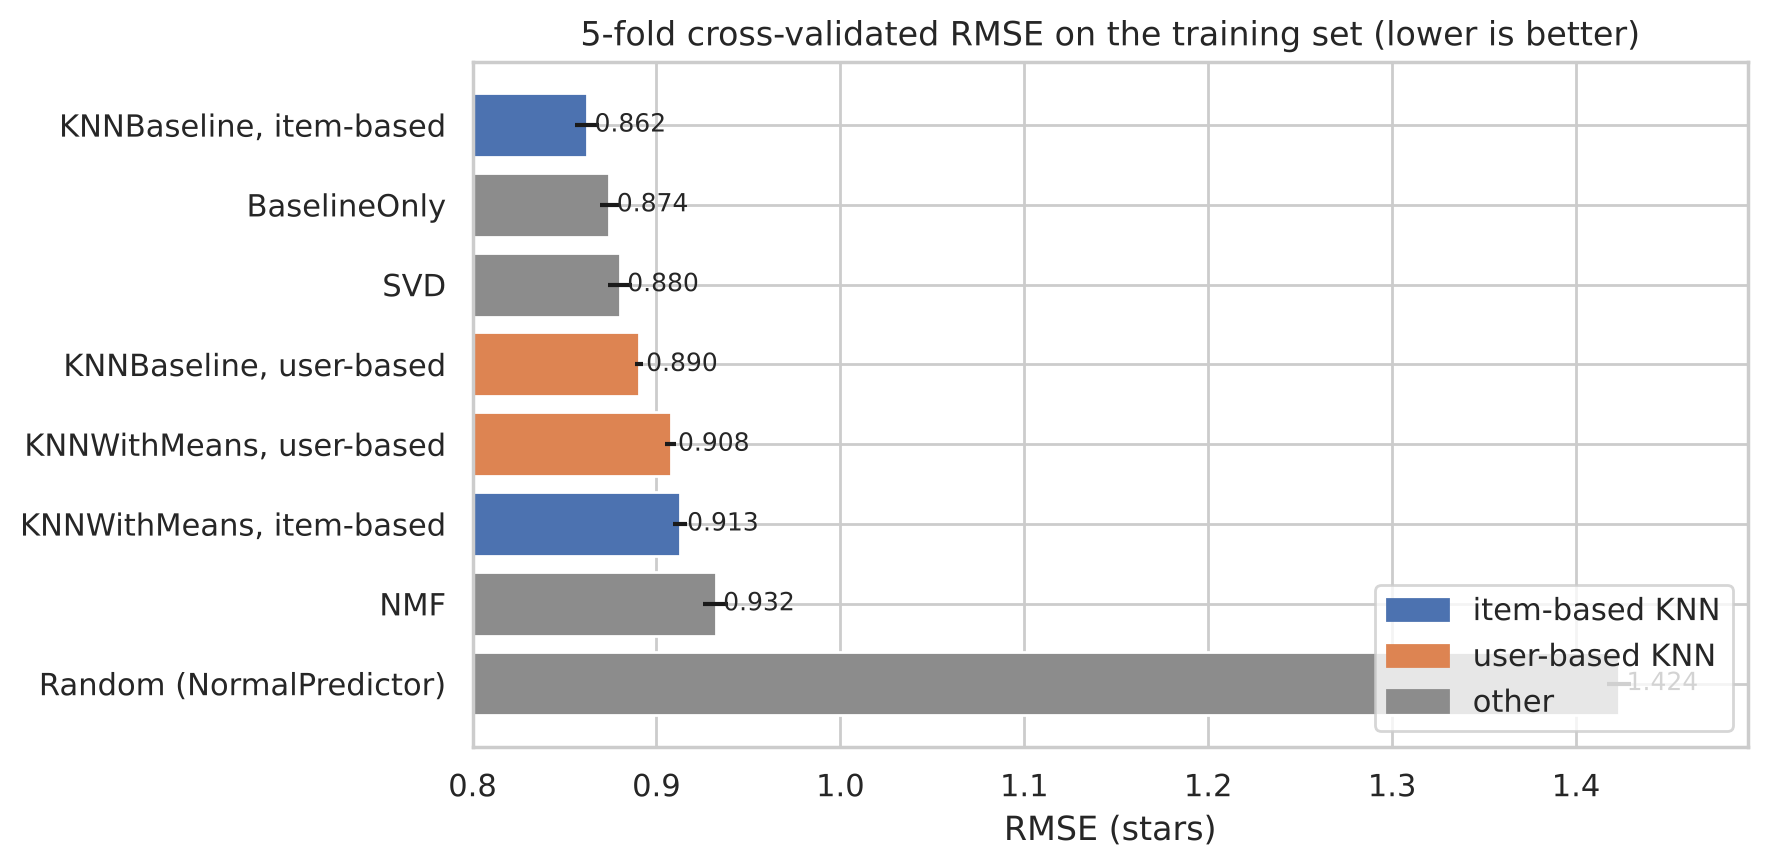

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_df = comparison.sort_values('RMSE', ascending=False)
colors = ['#4C72B0' if 'item' in m else '#DD8452' if 'user' in m else '#8C8C8C' for m in plot_df['model']]
ax.barh(plot_df['model'], plot_df['RMSE'], xerr=plot_df['RMSE_std'], color=colors)
for i, v in enumerate(plot_df['RMSE']):
    ax.text(v + 0.004, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlim(0.8, plot_df['RMSE'].max() + 0.07)
ax.set(title='5-fold cross-validated RMSE on the training set (lower is better)', xlabel='RMSE (stars)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#4C72B0', label='item-based KNN'), Patch(color='#DD8452', label='user-based KNN'),
                   Patch(color='#8C8C8C', label='other')], loc='lower right')
plt.tight_layout()
plt.show()

**What the comparison shows**
* Every model beats random guessing by a wide margin (RMSE ≈ 1.42 → ≈ 0.86–0.93).
* **Item-based KNNBaseline is the best untuned model** (RMSE 0.862), and the only one that clearly beats BaselineOnly (0.875).
* **BaselineOnly is a tough benchmark.** Much of what drives a rating is just *"is this a generous user?"* and *"is this a well-loved movie?"*.
* **Item-based beats user-based** when both use `pearson_baseline` (0.862 vs 0.890).
* **Removing biases before comparing matters a lot.** Both KNN types do much better with `pearson_baseline` (KNNBaseline) than with plain `pearson` (KNNWithMeans).
* **SVD with default settings (0.880) is slightly behind the baseline**, but its defaults use very weak regularisation, so it should improve with tuning.

> **🧭 Decision: which models go forward to tuning?**
> **Item-based KNNBaseline** (best score now) and **SVD** (most room to improve). *How I decided:* I kept the best performer, plus the model whose weak score had a known, fixable cause (default regularisation of 0.02 is too weak for 98 %-empty data). NMF and the user-based models were clearly behind, so I dropped them.

## 4. Tune the two finalists

Each model has **hyperparameters**, settings chosen *before* training. I searched for the best settings with cross-validation on the training data.

### 4.1 SVD
* `n_factors`: how many hidden taste factors to learn
* `n_epochs`: how many passes over the data while learning
* `lr_all`: learning rate (how big each learning step is)
* `reg_all`: regularisation, which stops the model over-trusting users or movies with very few ratings

In [6]:
svd_grid = {
    'n_factors':   [50, 100, 150],
    'n_epochs':    [20, 30],
    'lr_all':      [0.005, 0.01],
    'reg_all':     [0.05, 0.1, 0.15],
    'random_state': [RANDOM_STATE],
}
gs = GridSearchCV(SVD, svd_grid, measures=['rmse', 'mae'], cv=folds, n_jobs=-1)
gs.fit(train_data)

svd_params = gs.best_params['rmse']
svd_cv = {'RMSE': gs.best_score['rmse'], 'MAE': gs.best_score['mae']}
print(f"Tried {len(gs.cv_results['params'])} combinations")
print('Best SVD settings:', {k: v for k, v in svd_params.items() if k != 'random_state'})
print(f"Best SVD CV RMSE: {svd_cv['RMSE']:.4f}   MAE: {svd_cv['MAE']:.4f}")

Tried 36 combinations
Best SVD settings: {'n_factors': 150, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1}
Best SVD CV RMSE: 0.8603   MAE: 0.6608


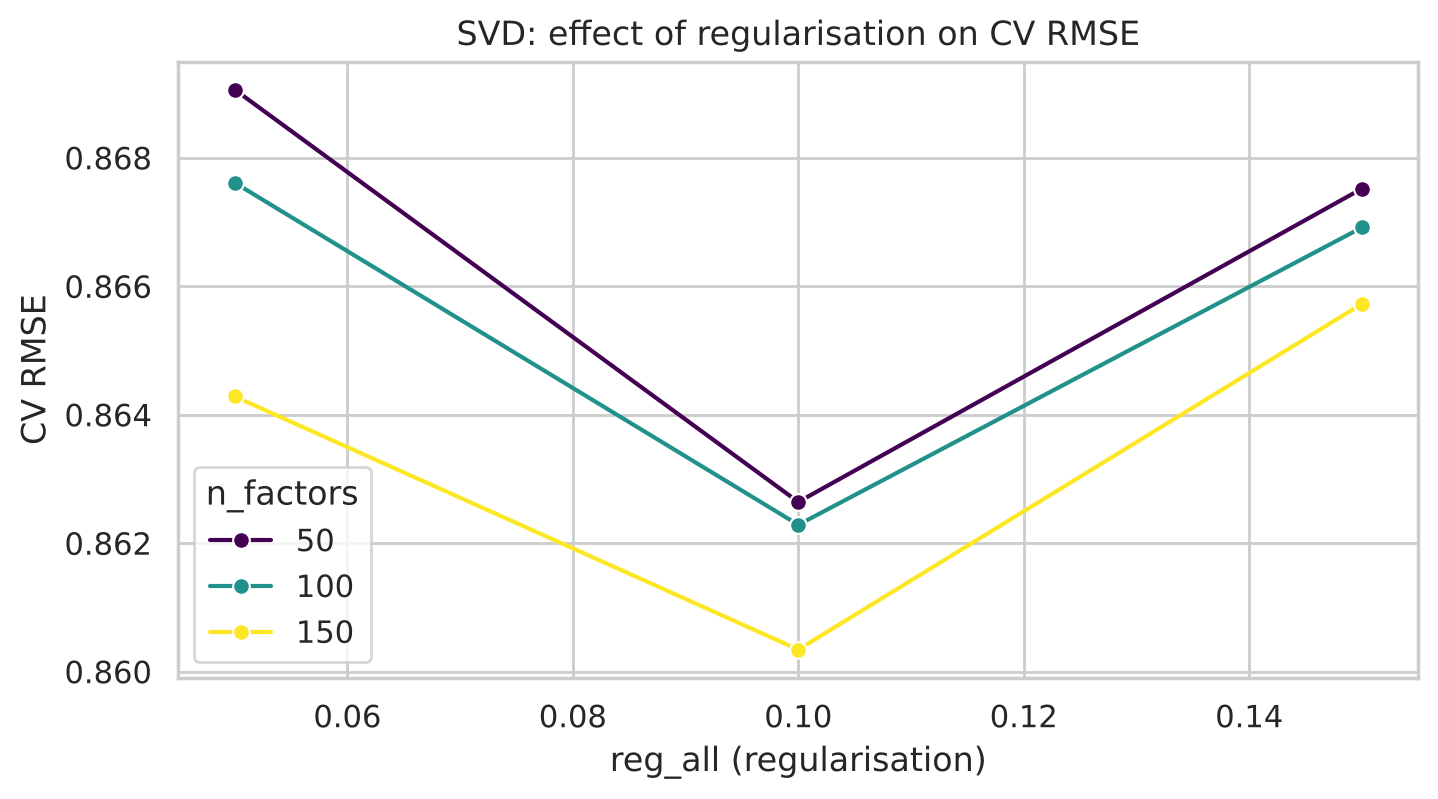

In [7]:
grid = pd.DataFrame(gs.cv_results)
fig, ax = plt.subplots(figsize=(8, 4))
sub = grid[(grid.param_n_epochs == svd_params['n_epochs']) & (grid.param_lr_all == svd_params['lr_all'])]
sns.lineplot(data=sub, x='param_reg_all', y='mean_test_rmse', hue='param_n_factors', marker='o', palette='viridis', ax=ax)
ax.set(title='SVD: effect of regularisation on CV RMSE', xlabel='reg_all (regularisation)', ylabel='CV RMSE')
ax.legend(title='n_factors')
plt.show()

> **🧭 Decision: how I tuned SVD.** *How I decided:* I tried every combination of 3–4 sensible values around the library defaults (36 combinations in total), scored each with the same 5 folds, and kept the lowest RMSE. That's a **grid search**: no guessing, and every option is tested the same way.

Regularisation matters most. The default (0.02) is far too weak for data that is 98 % empty. Around 0.1 the model stops over-fitting users and movies with only a handful of ratings.

### 4.2 Item-based KNN (KNNBaseline)
The key setting is **`k`**, how many similar movies to use for each prediction. Too few and predictions are noisy. Too many and less-similar movies dilute them.

In [8]:
knn_rows = []
for k in [20, 40, 60, 80]:
    algo = KNNBaseline(k=k, sim_options=item_sim('pearson_baseline'), verbose=False)
    res = cross_validate(algo, train_data, measures=['RMSE', 'MAE'], cv=folds, n_jobs=1)
    knn_rows.append({'k': k, 'RMSE': res['test_rmse'].mean(), 'MAE': res['test_mae'].mean()})
    print(f'k={k:3d}  RMSE {res["test_rmse"].mean():.4f}   MAE {res["test_mae"].mean():.4f}')

knn_tuning = pd.DataFrame(knn_rows)
best_k = int(knn_tuning.loc[knn_tuning.RMSE.idxmin(), 'k'])
knn_cv = knn_tuning.loc[knn_tuning.RMSE.idxmin(), ['RMSE', 'MAE']].to_dict()
print(f'Best k = {best_k}')

k= 20  RMSE 0.8648   MAE 0.6600


k= 40  RMSE 0.8623   MAE 0.6583


k= 60  RMSE 0.8622   MAE 0.6584


k= 80  RMSE 0.8624   MAE 0.6586
Best k = 60


> **🧭 Decision: k for item-based KNN.** *How I decided:* I tried k = 20, 40, 60 and 80 on the same folds and kept the lowest RMSE. Scores flatten out after about 40, so the exact choice barely matters.

### 4.3 Finalists after tuning

In [9]:
baseline_row = comparison.set_index('model').loc['BaselineOnly']
finalists = pd.DataFrame([
    {'model': 'BaselineOnly (benchmark)', 'RMSE': baseline_row.RMSE, 'MAE': baseline_row.MAE},
    {'model': f'Item-based KNN (k={best_k})', 'RMSE': knn_cv['RMSE'], 'MAE': knn_cv['MAE']},
    {'model': f"SVD (tuned, {svd_params['n_factors']} factors)", 'RMSE': svd_cv['RMSE'], 'MAE': svd_cv['MAE']},
])
finalists['RMSE gain vs baseline'] = (1 - finalists.RMSE / baseline_row.RMSE).map('{:.1%}'.format)
finalists.round(4)

,model,RMSE,MAE,RMSE gain vs baseline
0,BaselineOnly (benchmark),0.8745,0.6752,0.0%
1,Item-based KNN (k=60),0.8622,0.6584,1.4%
2,"SVD (tuned, 150 factors)",0.8603,0.6608,1.6%


**It's effectively a tie.** Tuned SVD has slightly lower RMSE (0.860 vs 0.862), and item-based KNN has slightly lower MAE (0.658 vs 0.661). Both differences are about 0.002 stars, smaller than the variation between folds (≈ 0.006). Statistically they can't be separated.

> **🧭 Decision: final model = SVD.** *How I decided:* accuracy couldn't separate the two, so I used practical criteria as the tie-breaker:
> 1. **Size and speed.** SVD stores ~150 numbers per user and per movie. Item-based KNN must store a similarity score for every pair of movies (~650 MB). SVD is much easier for Julie to use in Phase 5.
> 2. **It can be extended.** New users' ratings can be folded in by refitting in a few seconds, and SVD is the usual starting point for hybrid recommenders.
> 3. **It's the most-used CF method in practice** (it won the Netflix Prize), so it's well documented.
>
> I kept **item-based KNN as the runner-up** and give James its predictions too, so Phase 4 can check the choice on the test set.

## 5. Train the final model and predict ratings for unseen movies

I trained tuned SVD on the **full training set** (not just 4/5 of it as in cross-validation).

I then generated a predicted rating for every pair in Sheilla's **test set**. Those movies are *unseen* by the model for those users. **I don't score the predictions here.** I saved them so James can calculate RMSE and MAE in Phase 4. I did the same for the runner-up, item-based KNN, so James can compare the two.

In [10]:
final_model = SVD(**svd_params)
final_model.fit(trainset)

runner_up = KNNBaseline(k=best_k, sim_options=item_sim('pearson_baseline'), verbose=False)
runner_up.fit(trainset)

testset = [(u, m, float(r)) for u, m, r in test[cols].itertuples(index=False)]
known_movies = set(train.movieId)

def predictions_table(model, model_name):
    preds = model.test(testset)
    return pd.DataFrame({
        'userId': [p.uid for p in preds],
        'movieId': [p.iid for p in preds],
        'actual_rating': [p.r_ui for p in preds],
        'predicted_rating': [round(p.est, 4) for p in preds],
        'movie_in_train': [p.iid in known_movies for p in preds],
        'model': model_name,
    })

pred_svd = predictions_table(final_model, 'SVD')
pred_knn = predictions_table(runner_up, f'ItemKNN_k{best_k}')
pred_svd.head()

,userId,movieId,actual_rating,predicted_rating,movie_in_train,model
0,1,3578,5.0,4.5977,True,SVD
1,1,1127,4.0,4.2568,True,SVD
2,1,157,5.0,3.7023,True,SVD
3,1,2617,2.0,3.9873,True,SVD
4,1,260,5.0,4.9774,True,SVD


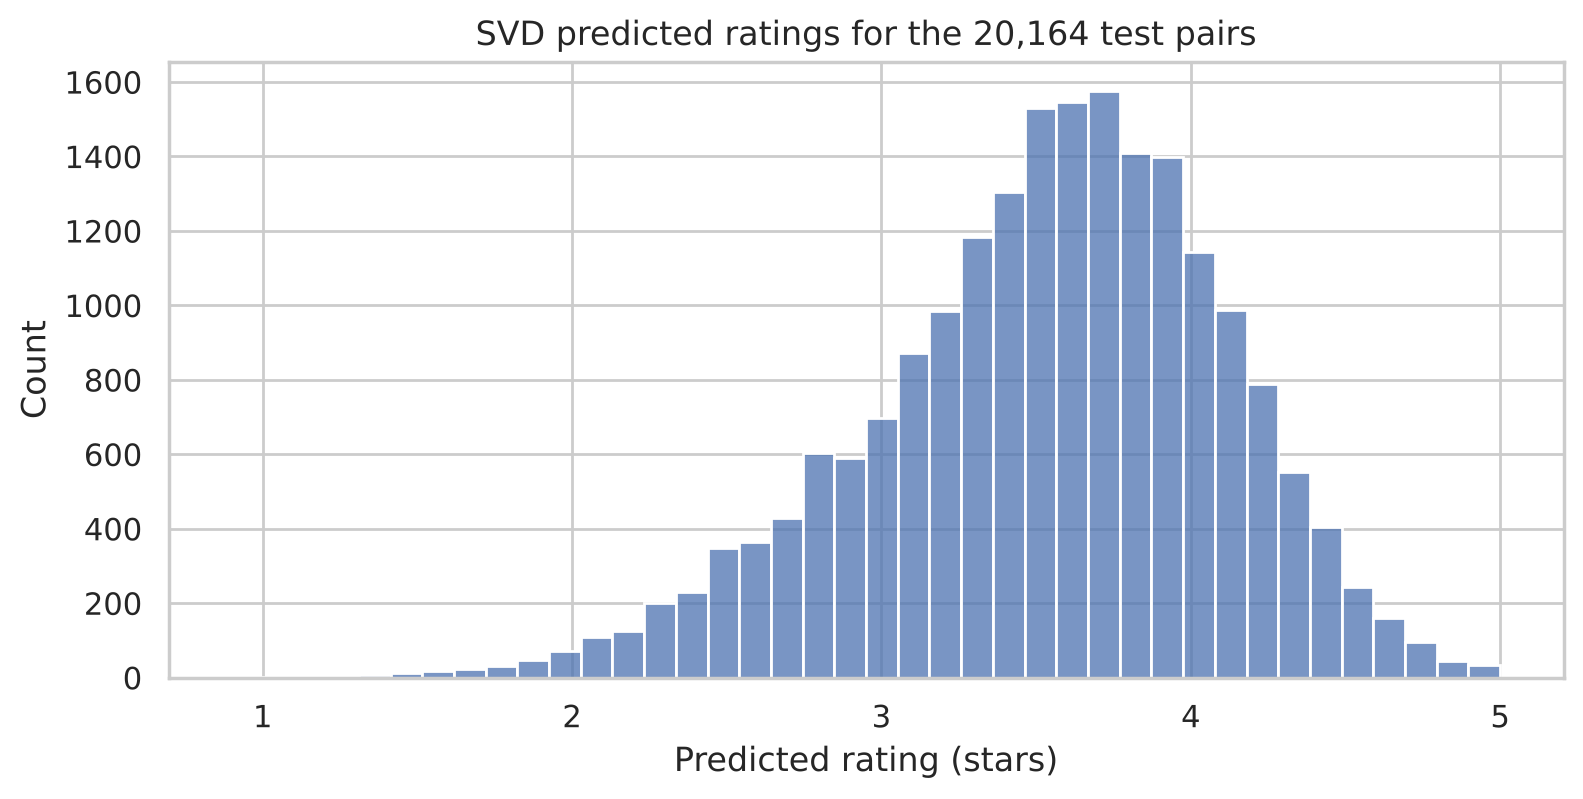

count    20164.00
mean         3.53
std          0.57
min          0.90
25%          3.18
50%          3.59
75%          3.93
max          5.00
Name: predicted_rating, dtype: float64

SVD     : 790 predictions for movies not in training -> 150 distinct values, mean 3.37
Item KNN: 790 predictions for movies not in training -> 151 distinct values, mean 3.31


In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(pred_svd.predicted_rating, bins=40, color='#4C72B0', ax=ax)
ax.set(title='SVD predicted ratings for the 20,164 test pairs', xlabel='Predicted rating (stars)', ylabel='Count')
plt.show()

print(pred_svd.predicted_rating.describe().round(2))
print()
for name, p in [('SVD', pred_svd), ('Item KNN', pred_knn)]:
    unk = p[~p.movie_in_train]
    print(f'{name:8s}: {len(unk)} predictions for movies not in training -> '
          f'{unk.predicted_rating.nunique()} distinct values, mean {unk.predicted_rating.mean():.2f}')

**Unseen movies (the 790 pairs)**
Both models handle these the same way. They predict the **global average plus that user's bias**, so a generous rater gets a higher guess than a harsh one. Nothing is known about the movie itself. That's why there are only as many distinct values as there are users involved: every unseen movie gets the same guess for a given user.

Neither model can really judge a movie nobody has rated. That's the **cold start** problem that James investigates in Phase 4, and it's why a content-based fallback using genres and tags is useful.

> **🧭 Decision: don't score test predictions in Phase 3, and give James both models' predictions.** *How I decided:* the project plan gives evaluation to Phase 4. Keeping the test set unscored while choosing my model keeps James's results honest. Passing both finalists' predictions lets him check my tie-break on fresh data.

In [12]:
# Save everything the next phases need
pred_svd.to_csv(OUTPUT_DIR + 'test_predictions_svd.csv', index=False)
pred_knn.to_csv(OUTPUT_DIR + 'test_predictions_itemknn.csv', index=False)
dump.dump(OUTPUT_DIR + 'svd_model.pkl', algo=final_model)
pd.DataFrame([{**{k: v for k, v in svd_params.items()}, 'item_knn_best_k': best_k,
               'svd_cv_rmse': svd_cv['RMSE'], 'svd_cv_mae': svd_cv['MAE'],
               'itemknn_cv_rmse': knn_cv['RMSE'], 'itemknn_cv_mae': knn_cv['MAE']}]
             ).to_csv(OUTPUT_DIR + 'model_settings.csv', index=False)

for f in sorted(os.listdir(OUTPUT_DIR)):
    print(f'{f:32s} {os.path.getsize(OUTPUT_DIR + f) / 1024:>8.0f} KB')

# Anyone can reload the trained model later with:
_, reloaded = dump.load(OUTPUT_DIR + 'svd_model.pkl')
assert abs(reloaded.predict(1, 1).est - final_model.predict(1, 1).est) < 1e-9
print('\nSaved model reloads and gives identical predictions.')

model_settings.csv                      0 KB
svd_model.pkl                       13618 KB
test_predictions_itemknn.csv          725 KB
test_predictions_svd.csv              567 KB

Saved model reloads and gives identical predictions.


## 6. The recommendation function: top 5 for a user

**How it works, step by step**
1. Take every movie the user has **not** rated in the training data.
2. Keep only movies with **at least *N* ratings** in training. A movie rated 5 stars by one person isn't reliable evidence that it's good. *Sheilla deliberately left this filtering to the modelling stage.* I chose *N* with data in Section 6.1.
3. Predict the user's rating for each remaining movie with SVD.
4. Sort from highest to lowest and return the **top 5**.

> **🧭 Decision: exclude movies the user already rated.** *How I decided:* recommending something they've already seen is useless. I exclude movies they rated in **training**. Their test-set movies are still "unseen" by the model, so they can still be recommended.

*Detail:* Surprise caps predictions at 5 stars. For ranking I use the uncapped estimate (`clip=False`), so generous raters don't end up with many ties at exactly 5.0. The displayed rating is still capped at 5.

In [13]:
train_counts = train.groupby('movieId').size()
movie_info = movies.set_index('movieId')

def recommend_top5(user_id, model=final_model, n=5, min_ratings=None):
    """Return the top-n movies a user hasn't rated, ranked by predicted rating."""
    min_ratings = MIN_RATINGS if min_ratings is None else min_ratings
    eligible = train_counts[train_counts >= min_ratings].index
    already_rated = set(train.loc[train.userId == user_id, 'movieId'])
    candidates = [m for m in eligible if m not in already_rated]
    scored = [(m, model.predict(user_id, m, clip=False).est) for m in candidates]
    top = sorted(scored, key=lambda x: x[1], reverse=True)[:n]
    ids = [m for m, _ in top]
    return pd.DataFrame({
        'rank': range(1, len(ids) + 1),
        'movieId': ids,
        'title': movie_info.loc[ids, 'title'].values,
        'genres': movie_info.loc[ids, 'genre_list'].fillna('').values,
        'predicted_rating': [round(min(s, 5.0), 2) for _, s in top],
    }).set_index('rank')

def favourites(user_id, n=5):
    fav = train[train.userId == user_id].sort_values(['rating', 'timestamp'], ascending=False).head(n)
    return pd.DataFrame({'title': movie_info.loc[fav.movieId, 'title'].values,
                         'genres': movie_info.loc[fav.movieId, 'genre_list'].fillna('').values,
                         'their_rating': fav.rating.values})

### 6.1 Choosing the minimum number of ratings (*N*)
My first attempt used *N* = 10, and one movie, *Guess Who's Coming to Dinner*, came out **#1 for almost every user**. The reason: it has exactly 10 training ratings averaging 4.6 stars, so the model learned a very large "everyone loves this" bias from only 10 people.

That clashes with the group's **objective 2: variety**. So I tested several values of *N* on 150 random users and measure:
* **Distinct movies recommended**: how many different movies appear across all their top-5 lists. More means more variety.
* **Share of users given the single most common movie**: lower means no one movie dominates.

In [14]:
rng = np.random.default_rng(RANDOM_STATE)
sample_users = rng.choice(train.userId.unique(), size=150, replace=False)

rows = []
for n_min in [5, 10, 20, 30, 50]:
    lists = [recommend_top5(u, min_ratings=n_min).movieId.tolist() for u in sample_users]
    counts = pd.Series([m for lst in lists for m in lst]).value_counts()
    rows.append({'min_ratings': n_min,
                 'eligible_movies': int((train_counts >= n_min).sum()),
                 'distinct_movies_recommended': counts.size,
                 'most_common_movie': movie_info.loc[counts.index[0], 'title'],
                 'share_of_users_getting_it': counts.iloc[0] / len(sample_users)})
threshold_test = pd.DataFrame(rows)
MIN_RATINGS = int(threshold_test.loc[threshold_test.distinct_movies_recommended.idxmax(), 'min_ratings'])
display(threshold_test.style.format({'share_of_users_getting_it': '{:.0%}'}).hide(axis='index'))
print(f'Chosen minimum: {MIN_RATINGS} ratings (gives the most variety)')

min_ratings,eligible_movies,distinct_movies_recommended,most_common_movie,share_of_users_getting_it
5,3217,83,Guess Who's Coming to Dinner (1967),75%
10,1939,91,Guess Who's Coming to Dinner (1967),85%
20,1051,86,"Grand Day Out with Wallace and Gromit, A (1989)",55%
30,704,93,Singin' in the Rain (1952),65%
50,312,83,"Shawshank Redemption, The (1994)",52%


Chosen minimum: 30 ratings (gives the most variety)


**What this shows**
* With a minimum of 5 or 10 ratings, *Guess Who's Coming to Dinner* (rated by only 10 people in training) lands in **75–85 % of users' top 5**. That's not useful.
* A minimum of **30** gives the most variety (93 different movies) and removes that problem.
* Even so, variety is limited. About 90 different movies fill 750 recommendation slots, and one popular classic still reaches ~65 % of users. SVD with strong regularisation leans on each movie's overall "quality" bias, so well-loved classics dominate. That's a **known weakness**, and a direct input for **objective 2**, which James can measure fully in Phase 4.

> **🧭 Decision: only recommend movies with at least 30 training ratings.** *How I decided:* I didn't pick a number by feel. I tested 5, 10, 20, 30 and 50 on 150 random users and chose the value that gave the **most different movies** across their lists, because variety is the group's objective 2. The code picks it automatically (`idxmax`), so the rule is repeatable.

### 6.2 Top 5 for selected users
I picked three different kinds of user: a **light** user (few ratings), a **typical** user (around the median), and the **heaviest** user. Showing each user's favourites next to the recommendations is a quick sanity check: do the picks make sense for this person?

In [15]:
user_counts = train.groupby('userId').size()
selected_users = {
    # fewest ratings among users who don't give every movie the same score (someone who rates everything 5 stars gives little information)
    'Light user': user_counts[train.groupby('userId').rating.std() >= 0.5].idxmin(),
    'Typical user': (user_counts - user_counts.median()).abs().idxmin(),
    'Heaviest user': user_counts.idxmax(),
}
for label, uid in selected_users.items():
    print(f'{label}: userId {uid} with {user_counts[uid]} training ratings '
          f'(average rating they give: {train[train.userId == uid].rating.mean():.2f})')

Light user: userId 147 with 16 training ratings (average rating they give: 3.53)
Typical user: userId 86 with 56 training ratings (average rating they give: 3.96)
Heaviest user: userId 414 with 2158 training ratings (average rating they give: 3.39)


In [16]:
uid = selected_users['Light user']
print(f'USER {uid}: favourites from their ratings')
display(favourites(uid))
print(f'USER {uid}: top 5 recommendations')
recommend_top5(uid)

USER 147: favourites from their ratings


,title,genres,their_rating
0,Star Trek IV: The Voyage Home (1986),Adventure|Comedy|Sci-Fi,5.0
1,Disclosure (1994),Drama|Thriller,5.0
2,Chasing Amy (1997),Comedy|Drama|Romance,5.0
3,"Three Musketeers, The (1993)",Action|Adventure|Comedy|Romance,4.5
4,True Romance (1993),Crime|Thriller,4.5


USER 147: top 5 recommendations


,movieId,title,genres,predicted_rating
rank,,,,
1,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.52
2,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.51
3,899,Singin' in the Rain (1952),Comedy|Musical|Romance,4.50
4,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.50
5,2019,Seven Samurai (Shichinin no samurai) (1954),Action|Adventure|Drama,4.50


In [17]:
uid = selected_users['Typical user']
print(f'USER {uid}: favourites from their ratings')
display(favourites(uid))
print(f'USER {uid}: top 5 recommendations')
recommend_top5(uid)

USER 86: favourites from their ratings


,title,genres,their_rating
0,Mr. & Mrs. Smith (2005),Action|Adventure|Comedy|Romance,5.0
1,"Imaginarium of Doctor Parnassus, The (2009)",Drama|Fantasy,4.5
2,Cloudy with a Chance of Meatballs (2009),Animation|Children|Fantasy|IMAX,4.5
3,Partly Cloudy (2009),Animation|Children|Comedy|Fantasy,4.5
4,Coraline (2009),Animation|Fantasy|Thriller,4.5


USER 86: top 5 recommendations


,movieId,title,genres,predicted_rating
rank,,,,
1,899,Singin' in the Rain (1952),Comedy|Musical|Romance,4.53
2,1276,Cool Hand Luke (1967),Drama,4.43
3,1233,"Boot, Das (Boat, The) (1981)",Action|Drama|War,4.40
4,1252,Chinatown (1974),Crime|Film-Noir|Mystery|Thriller,4.39
5,904,Rear Window (1954),Mystery|Thriller,4.39


In [18]:
uid = selected_users['Heaviest user']
print(f'USER {uid}: favourites from their ratings')
display(favourites(uid))
print(f'USER {uid}: top 5 recommendations')
recommend_top5(uid)

USER 414: favourites from their ratings


,title,genres,their_rating
0,"Secret Life of Walter Mitty, The (2013)",Adventure|Comedy|Drama,5.0
1,Seven Samurai (Shichinin no samurai) (1954),Action|Adventure|Drama,5.0
2,Band of Brothers (2001),Action|Drama|War,5.0
3,The Revenant (2015),Adventure|Drama,5.0
4,Brooklyn (2015),Drama|Romance,5.0


USER 414: top 5 recommendations


,movieId,title,genres,predicted_rating
rank,,,,
1,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.62
2,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.58
3,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.54
4,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.49
5,4226,Memento (2000),Mystery|Thriller,4.49


**Reading the three examples**
* All three users get **highly rated, well-known films**, and there is real overlap (*Fight Club*, *Pulp Fiction*, *Shawshank*). That's the "quality bias" effect from Section 6.1.
* There is still **personalisation**. The typical user (86), who rates generously and likes fantasy and animation, gets older lighter classics such as *Singin' in the Rain* and *Rear Window*. The heaviest user (414) gets crime and drama, in line with the war and drama films they rated 5 stars.
* For the light user (147, only 16 ratings), the list is almost pure "best-loved movies". With little data, the model falls back on movie quality. That's the **cold start** effect in action.

> **🧭 Decision: show three kinds of user.** *How I decided:* I picked users to show how the model behaves across the range: the fewest ratings, the median, and the most. For the light user I skipped people who give every movie the same score, because someone who rates everything 5 stars gives the model no information about taste.

## 7. Summary

| Task (from the project plan) | Done | Where |
|---|---|---|
| Research CF techniques | ✅ | Section 1 |
| Implement a CF model | ✅ | Sections 3–5 |
| Explore user-based **and** item-based CF | ✅ Both, with two similarity measures each | Section 3 |
| Train using the prepared data | ✅ Sheilla's `train.csv`, unchanged | Sections 2, 5 |
| Predict ratings for unseen movies | ✅ All 20,164 test pairs | Section 5 |
| Top 5 for selected users | ✅ `recommend_top5()`, shown for 3 users | Section 6 |

**Final model:** SVD (150 factors, 30 epochs, learning rate 0.01, regularisation 0.1). Cross-validated RMSE **0.860**, MAE **0.661** on the training data, about 1.6 % better than the baseline. Item-based KNN (k = 60) is a statistically tied runner-up. Recommendations are limited to movies with at least **30** training ratings.

### Output files (`phase3_outputs/`)
| File | Used in | Contents |
|---|---|---|
| `test_predictions_svd.csv` | Phase 4 | Actual vs predicted rating for all 20,164 test pairs from the final SVD model, plus a `movie_in_train` flag |
| `test_predictions_itemknn.csv` | Phase 4 | The same for the runner-up item-based KNN |
| `svd_model.pkl` | Phase 5 | The trained model. Load with `_, model = dump.load('svd_model.pkl')` |
| `model_settings.csv` | All | Chosen settings and cross-validation scores |